# MLP residual — correção da persistência de cinco minutos

Resolução real de **cinco minutos**, horizonte **t+5 minutos**. Os nomes dos arquivos foram mantidos por solicitação do usuário; o conteúdo foi migrado de diário para intradiário.

O alvo e a persistência (t−5 min) precisam ser originalmente medidos. Cada etapa de preenchimento causal usa até 15 minutos; no Brasil a combinação proxy + ffill pode atingir 30 minutos somente no histórico: nunca se interpola usando ponto posterior. Não se concatenam blocos interrompidos. A avaliação principal é diurna (elevação solar > 0); a avaliação 24h é complementar. Zero noturno não deve inflar a precisão.

As entradas principais são potência AC em p.u., hora local e dia do ano em seno/cosseno. O vento continua excluído. ERA5 nativa horária é auxiliar e não entra nos modelos principais. Estatísticas de normalização vêm apenas do treino australiano; alvos de validação/teste não ajustam escalas.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
RAIZ=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/energia_transfer').is_dir())
if str(RAIZ/'src') not in sys.path: sys.path.insert(0,str(RAIZ/'src'))
PASTA=RAIZ/'experimentos/transfer_learning_australia_brasil'
AU=RAIZ/'experimentos/australia_deep_learning'
REPORT=RAIZ/'reports/intradiario'
from energia_transfer.transfer_learning.dados import carregar,particao
_,CONFIG,CONTRATO=carregar(PASTA)
def exibir(t): display(t.round(5))


Positivo: residual com menor RMSE que a direta no mesmo lag e semente. Sem escolher semente pelo teste.


,lag,seed,lstm_direta,mlp_direta,mlp_residual,ganho_residual_sobre_direta_pct
0,6,7,1.13632,1.14107,1.12197,1.67455
1,6,21,1.14022,1.14315,1.12449,1.63263
2,6,42,1.13831,1.13668,1.12424,1.09446
3,6,84,1.14831,1.13463,1.12318,1.00918
4,6,123,1.15018,1.14056,1.12572,1.30093
5,12,7,1.13097,1.13722,1.12209,1.32970
6,12,21,1.13586,1.14658,1.12026,2.29501
7,12,42,1.13219,1.12831,1.11955,0.77626
8,12,84,1.15116,1.13515,1.12421,0.96438
9,12,123,1.14148,1.13322,1.12209,0.98189


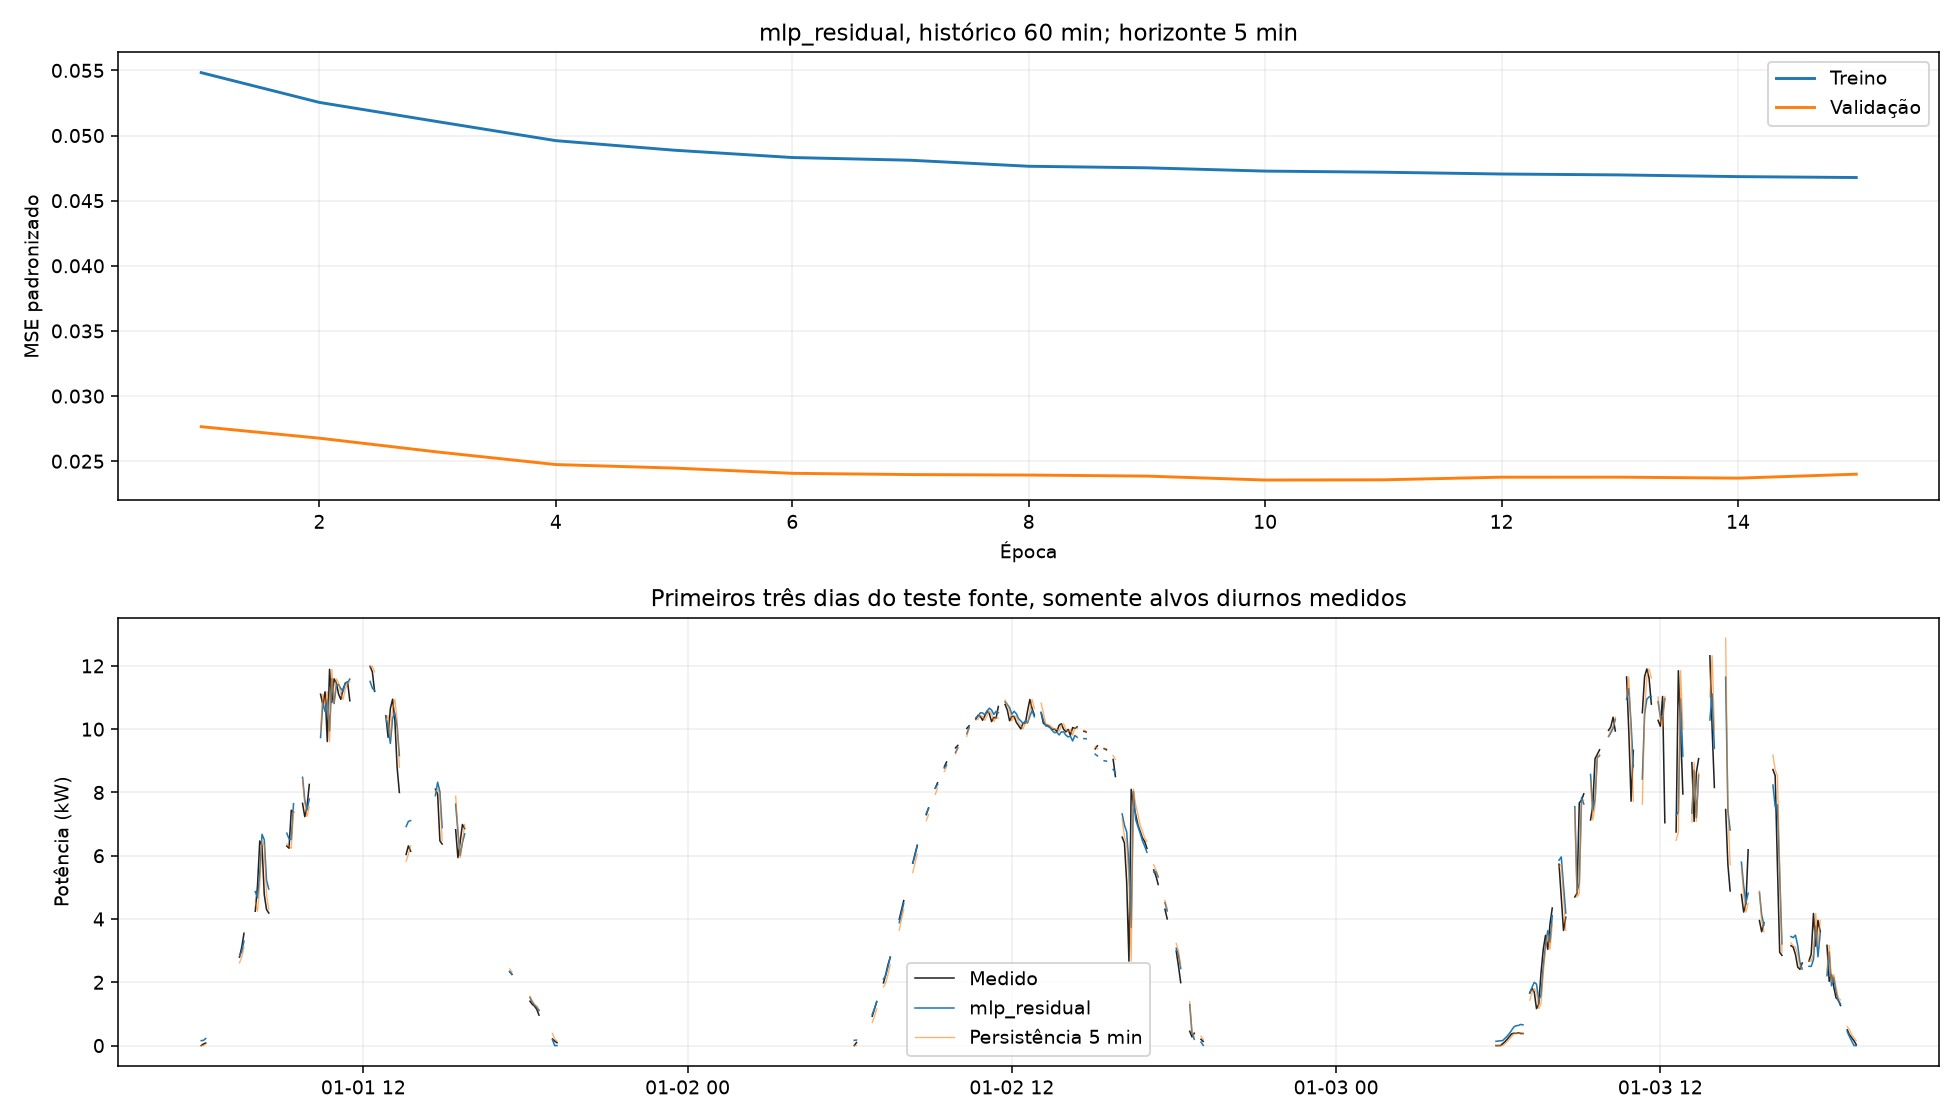

In [2]:
exibir(pd.read_csv(AU/'resultados/correcao_persistencia_5min.csv'))
display(Image(filename=str(AU/'figuras/treino_mlp_residual.png')))
print('Positivo: residual com menor RMSE que a direta no mesmo lag e semente. Sem escolher semente pelo teste.')
